In [7]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("="*60)
print("Dataset Loaded Successfully")
print("="*60)

print(df.head())

Saving Battery_Data_Cleaned.csv to Battery_Data_Cleaned (1).csv
Dataset Loaded Successfully
   type  ambient_temperature  battery_id  test_id  uid   filename  Capacity  \
0    -1                    4          47        0    1  00001.csv  0.983689   
1     0                   24          47        1    2  00002.csv  0.983689   
2     1                    4          47        2    3  00003.csv  0.983689   
3     0                   24          47        3    4  00004.csv  0.983689   
4    -1                    4          47        4    5  00005.csv  0.925990   

         Re       Rct  
0  0.054543  0.183130  
1  0.054543  0.183130  
2  0.054543  0.183130  
3  0.051825  0.152493  
4  0.051825  0.152493  



COLUMNS
  - type
  - ambient_temperature
  - battery_id
  - test_id
  - uid
  - filename
  - Capacity
  - Re
  - Rct

DATA TYPES
type                     int64
ambient_temperature      int64
battery_id               int64
test_id                  int64
uid                      int64
filename                object
Capacity               float64
Re                     float64
Rct                    float64
dtype: object

FIRST FIVE RECORDS
   type  ambient_temperature  battery_id  test_id  uid   filename  Capacity  \
0    -1                    4          47        0    1  00001.csv  0.983689   
1     0                   24          47        1    2  00002.csv  0.983689   
2     1                    4          47        2    3  00003.csv  0.983689   
3     0                   24          47        3    4  00004.csv  0.983689   
4    -1                    4          47        4    5  00005.csv  0.925990   

         Re       Rct  
0  0.054543  0.183130  
1  0.054543  0.183130  
2  0.05454

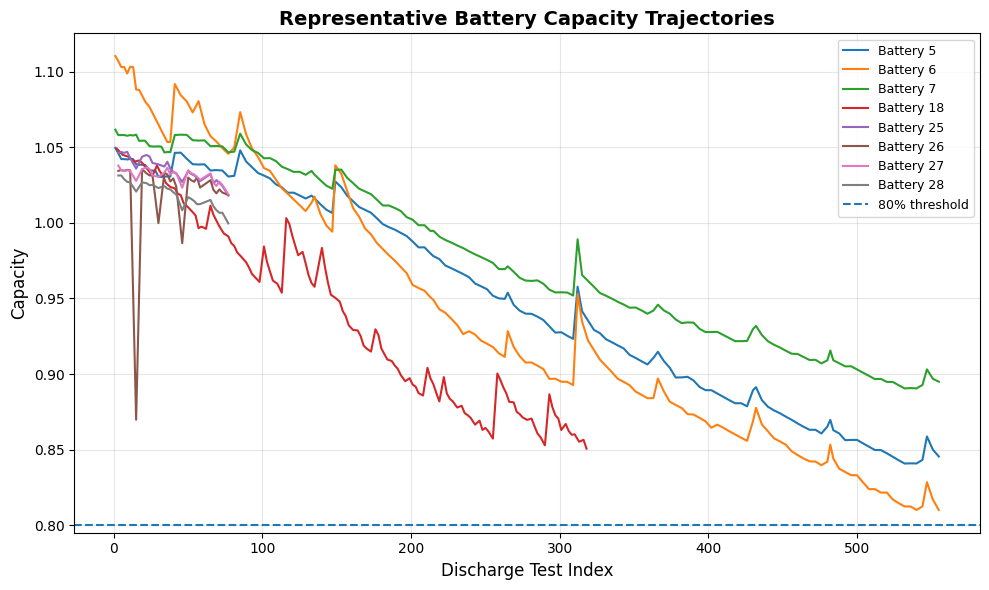


STEP 1 COMPLETE


In [9]:
# ============================================================
# STEP 1 — BATTERY DATASET AUDIT
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# # ------------------------------------------------------------
# # 1. LOAD DATASET
# # ------------------------------------------------------------

# DATA_PATH = Path("/content/Battery_Data_Cleaned(2).csv")

# if not DATA_PATH.exists():
#     raise FileNotFoundError(
#         f"Dataset not found at: {DATA_PATH}"
#     )

# df = pd.read_csv(DATA_PATH)

# print("=" * 70)
# print("BATTERY DATASET AUDIT")
# print("=" * 70)

# print(f"Rows              : {len(df):,}")
# print(f"Columns           : {df.shape[1]}")
# print(
#     f"Unique batteries  : "
#     f"{df['battery_id'].nunique()}"
# )
# print(
#     f"Missing values    : "
#     f"{df.isna().sum().sum():,}"
# )


# ------------------------------------------------------------
# 2. COLUMN INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COLUMNS")
print("=" * 70)

for column in df.columns:
    print(f"  - {column}")


# ------------------------------------------------------------
# 3. DATA TYPES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA TYPES")
print("=" * 70)

print(df.dtypes)


# ------------------------------------------------------------
# 4. FIRST FIVE RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIRST FIVE RECORDS")
print("=" * 70)

print(df.head())


# ------------------------------------------------------------
# 5. DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DESCRIPTIVE STATISTICS")
print("=" * 70)

stats_columns = [
    "ambient_temperature",
    "Capacity",
    "Re",
    "Rct",
]

print(
    df[stats_columns]
    .describe()
    .round(4)
)


# ------------------------------------------------------------
# 6. BATTERY-LEVEL SUMMARY
# ------------------------------------------------------------

battery_summary = (
    df.groupby("battery_id")
    .agg(
        samples=("uid", "size"),
        capacity_min=("Capacity", "min"),
        capacity_max=("Capacity", "max"),
        capacity_mean=("Capacity", "mean"),
        re_mean=("Re", "mean"),
        rct_mean=("Rct", "mean"),
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("BATTERY-LEVEL SUMMARY")
print("=" * 70)

print(battery_summary.head(10))

print(
    f"\nMinimum samples per battery : "
    f"{battery_summary['samples'].min()}"
)

print(
    f"Maximum samples per battery : "
    f"{battery_summary['samples'].max()}"
)


# ------------------------------------------------------------
# 7. 80% CAPACITY THRESHOLD
# ------------------------------------------------------------

degraded_count = (
    df["Capacity"] <= 0.80
).sum()

healthy_count = (
    df["Capacity"] > 0.80
).sum()

print("\n" + "=" * 70)
print("80% CAPACITY HEALTH THRESHOLD")
print("=" * 70)

print(f"Healthy samples   : {healthy_count:,}")
print(f"Degraded samples  : {degraded_count:,}")

print(
    f"Degraded fraction : "
    f"{degraded_count / len(df):.2%}"
)


# ------------------------------------------------------------
# 8. BATTERY TYPE DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BATTERY TYPE DISTRIBUTION")
print("=" * 70)

print(
    df["type"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 9. AMBIENT TEMPERATURE DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("AMBIENT TEMPERATURES")
print("=" * 70)

print(
    df["ambient_temperature"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 10. CORRELATION ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRELATION MATRIX")
print("=" * 70)

correlation = (
    df[
        [
            "ambient_temperature",
            "Capacity",
            "Re",
            "Rct",
        ]
    ]
    .corr()
)

print(correlation.round(3))


# ------------------------------------------------------------
# 11. DISCHARGE EVENTS
# ------------------------------------------------------------

discharge_df = df[
    df["type"] == -1
].copy()

print("\n" + "=" * 70)
print("DISCHARGE-EVENT ANALYSIS")
print("=" * 70)

print(
    f"Discharge events    : "
    f"{len(discharge_df):,}"
)

print(
    f"Discharge batteries : "
    f"{discharge_df['battery_id'].nunique()}"
)


# ------------------------------------------------------------
# 12. DISCHARGE EVENTS PER BATTERY
# ------------------------------------------------------------

discharge_counts = (
    discharge_df
    .groupby("battery_id")
    .size()
)

print("\nDischarge events per battery:")

print(
    discharge_counts
    .describe()
    .round(2)
)


# ------------------------------------------------------------
# 13. CAPACITY TRAJECTORIES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

selected_batteries = (
    battery_summary["battery_id"]
    .head(8)
)

for battery_id in selected_batteries:

    battery_data = (
        discharge_df[
            discharge_df["battery_id"] == battery_id
        ]
        .sort_values("test_id")
    )

    plt.plot(
        battery_data["test_id"],
        battery_data["Capacity"],
        linewidth=1.5,
        label=f"Battery {battery_id}",
    )


plt.axhline(
    0.80,
    linestyle="--",
    linewidth=1.5,
    label="80% threshold",
)

plt.xlabel(
    "Discharge Test Index",
    fontsize=12,
)

plt.ylabel(
    "Capacity",
    fontsize=12,
)

plt.title(
    "Representative Battery Capacity Trajectories",
    fontsize=14,
    fontweight="bold",
)

plt.legend(fontsize=9)

plt.grid(
    True,
    alpha=0.3,
)

plt.tight_layout()


# ------------------------------------------------------------
# 14. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    "/content/Figure_1_capacity_trajectories.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    "/content/Figure_1_capacity_trajectories.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# FINAL MESSAGE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 1 COMPLETE")
print("=" * 70)

In [10]:
# ============================================================
# STEP 2 — CONSTRUCT BATTERY DEGRADATION EARLY-WARNING DATASET
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# # ------------------------------------------------------------
# # 1. LOAD DATA
# # ------------------------------------------------------------

# DATA_PATH = Path("/content/Battery_Data_Cleaned(2).csv")

# if not DATA_PATH.exists():
#     raise FileNotFoundError(
#         f"Dataset not found: {DATA_PATH}"
#     )

# df = pd.read_csv(DATA_PATH)


# ------------------------------------------------------------
# 2. KEEP ONLY DISCHARGE EVENTS
# ------------------------------------------------------------

research_df = df[
    df["type"] == -1
].copy()


# ------------------------------------------------------------
# 3. SORT EACH BATTERY CHRONOLOGICALLY
# ------------------------------------------------------------

research_df = research_df.sort_values(
    ["battery_id", "test_id"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 4. CREATE WITHIN-BATTERY DISCHARGE SEQUENCE
# ------------------------------------------------------------

research_df["cycle_no"] = (
    research_df
    .groupby("battery_id")
    .cumcount()
    + 1
)


# ------------------------------------------------------------
# 5. CURRENT ELECTROCHEMICAL FEATURES
# ------------------------------------------------------------

# Change in Re relative to previous discharge observation
research_df["delta_Re"] = (
    research_df
    .groupby("battery_id")["Re"]
    .diff()
)

# Change in Rct relative to previous discharge observation
research_df["delta_Rct"] = (
    research_df
    .groupby("battery_id")["Rct"]
    .diff()
)


# ------------------------------------------------------------
# 6. INITIAL BATTERY RESISTANCE
# ------------------------------------------------------------

initial_Re = (
    research_df
    .groupby("battery_id")["Re"]
    .transform("first")
)

initial_Rct = (
    research_df
    .groupby("battery_id")["Rct"]
    .transform("first")
)


# ------------------------------------------------------------
# 7. RESISTANCE DRIFT
# ------------------------------------------------------------

research_df["Re_drift_pct"] = (
    100.0
    * (research_df["Re"] - initial_Re)
    / initial_Re
)

research_df["Rct_drift_pct"] = (
    100.0
    * (research_df["Rct"] - initial_Rct)
    / initial_Rct
)


# ------------------------------------------------------------
# 8. ELECTROCHEMICAL RATIO
# ------------------------------------------------------------

research_df["Rct_Re_ratio"] = (
    research_df["Rct"]
    / research_df["Re"]
)


# ------------------------------------------------------------
# 9. NORMALIZED CYCLE
# ------------------------------------------------------------

research_df["log_cycle"] = np.log1p(
    research_df["cycle_no"]
)


# ------------------------------------------------------------
# 10. NEXT-DISCHARGE CAPACITY
# ------------------------------------------------------------

research_df["next_capacity"] = (
    research_df
    .groupby("battery_id")["Capacity"]
    .shift(-1)
)


# ------------------------------------------------------------
# 11. NEXT-CYCLE DEGRADATION TARGET
# ------------------------------------------------------------

research_df["next_degraded"] = np.where(
    research_df["next_capacity"].notna(),
    (research_df["next_capacity"] <= 0.80).astype(int),
    np.nan,
)


# ------------------------------------------------------------
# 12. REMOVE LAST OBSERVATION OF EACH BATTERY
# ------------------------------------------------------------

research_df = research_df[
    research_df["next_capacity"].notna()
].copy()


# ------------------------------------------------------------
# 13. REMOVE FIRST OBSERVATION FOR DELTA FEATURES
# ------------------------------------------------------------

research_df = research_df[
    research_df["delta_Re"].notna()
    & research_df["delta_Rct"].notna()
].copy()


# ------------------------------------------------------------
# 14. FINAL FEATURE SET
# ------------------------------------------------------------

FEATURES = [
    "ambient_temperature",
    "cycle_no",
    "log_cycle",
    "Re",
    "Rct",
    "delta_Re",
    "delta_Rct",
    "Re_drift_pct",
    "Rct_drift_pct",
    "Rct_Re_ratio",
]

TARGET = "next_degraded"


# ------------------------------------------------------------
# 15. NUMERICAL CLEANING
# ------------------------------------------------------------

research_df[FEATURES] = (
    research_df[FEATURES]
    .replace([np.inf, -np.inf], np.nan)
)

research_df = research_df.dropna(
    subset=FEATURES + [TARGET]
).copy()

research_df[TARGET] = (
    research_df[TARGET]
    .astype(int)
)


# ------------------------------------------------------------
# 16. DISPLAY FINAL DATASET INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("BATTERY EARLY-WARNING RESEARCH DATASET")
print("=" * 70)

print(
    f"Original observations       : "
    f"{len(df):,}"
)

print(
    f"Discharge observations      : "
    f"{len(df[df['type'] == -1]):,}"
)

print(
    f"Final research observations : "
    f"{len(research_df):,}"
)

print(
    f"Number of batteries         : "
    f"{research_df['battery_id'].nunique()}"
)

print(
    f"Number of features          : "
    f"{len(FEATURES)}"
)


# ------------------------------------------------------------
# 17. CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET DISTRIBUTION")
print("=" * 70)

class_counts = (
    research_df[TARGET]
    .value_counts()
    .sort_index()
)

print(class_counts)

print(
    f"\nNormal state     : "
    f"{class_counts.get(0, 0):,}"
)

print(
    f"Degraded state   : "
    f"{class_counts.get(1, 0):,}"
)

print(
    f"Degraded ratio   : "
    f"{research_df[TARGET].mean():.2%}"
)


# ------------------------------------------------------------
# 18. BATTERY DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLES PER BATTERY")
print("=" * 70)

battery_counts = (
    research_df
    .groupby("battery_id")
    .size()
)

print(
    battery_counts
    .describe()
    .round(2)
)


# ------------------------------------------------------------
# 19. FEATURE LIST
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL FEATURES")
print("=" * 70)

for number, feature in enumerate(FEATURES, start=1):
    print(f"{number:02d}. {feature}")


# ------------------------------------------------------------
# 20. CHECK FOR DATA LEAKAGE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)

for forbidden in [
    "Capacity",
    "next_capacity",
    "battery_id",
    "uid",
    "filename",
]:
    if forbidden in FEATURES:
        print(
            f"WARNING: {forbidden} is present in FEATURES"
        )
    else:
        print(
            f"OK: {forbidden} excluded from model inputs"
        )


# ------------------------------------------------------------
# 21. SAMPLE RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE RESEARCH RECORDS")
print("=" * 70)

display_columns = [
    "battery_id",
    "cycle_no",
    "ambient_temperature",
    "Re",
    "Rct",
    "delta_Re",
    "delta_Rct",
    "Re_drift_pct",
    "Rct_drift_pct",
    "Capacity",
    "next_capacity",
    "next_degraded",
]

print(
    research_df[display_columns]
    .head(15)
    .round(5)
)


# ------------------------------------------------------------
# 22. SAVE RESEARCH DATASET
# ------------------------------------------------------------

OUTPUT_PATH = (
    "/content/Battery_EarlyWarning_Dataset.csv"
)

research_df.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("\n" + "=" * 70)
print("DATASET SAVED")
print("=" * 70)

print(OUTPUT_PATH)


# ------------------------------------------------------------
# 23. FINAL SANITY CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SANITY CHECK")
print("=" * 70)

print(
    "NaN values in features :",
    research_df[FEATURES].isna().sum().sum(),
)

print(
    "NaN values in target   :",
    research_df[TARGET].isna().sum(),
)

print(
    "Infinite values        :",
    np.isinf(
        research_df[FEATURES].to_numpy()
    ).sum(),
)

print("\nSTEP 2 COMPLETE.")

BATTERY EARLY-WARNING RESEARCH DATASET
Original observations       : 7,368
Discharge observations      : 2,749
Final research observations : 2,681
Number of batteries         : 34
Number of features          : 10

TARGET DISTRIBUTION
next_degraded
0    1885
1     796
Name: count, dtype: int64

Normal state     : 1,885
Degraded state   : 796
Degraded ratio   : 29.69%

SAMPLES PER BATTERY
count     34.00
mean      78.85
std       54.46
min       23.00
25%       38.00
50%       67.50
75%      110.00
max      195.00
dtype: float64

MODEL FEATURES
01. ambient_temperature
02. cycle_no
03. log_cycle
04. Re
05. Rct
06. delta_Re
07. delta_Rct
08. Re_drift_pct
09. Rct_drift_pct
10. Rct_Re_ratio

LEAKAGE CHECK
OK: Capacity excluded from model inputs
OK: next_capacity excluded from model inputs
OK: battery_id excluded from model inputs
OK: uid excluded from model inputs
OK: filename excluded from model inputs

SAMPLE RESEARCH RECORDS
    battery_id  cycle_no  ambient_temperature       Re     Rct  

BATTERY-WISE EXPERIMENTAL SPLIT
Total batteries       : 34
Training batteries    : 27
Testing batteries     : 7
Training observations : 2,288
Testing observations  : 393

Training batteries:
[ 5  6  7 18 25 27 29 30 32 33 34 36 38 39 40 41 43 44 45 46 48 49 50 51
 53 54 55]

Testing batteries:
[26 28 31 42 47 52 56]

CLASS DISTRIBUTION

Training:
next_degraded
0    1658
1     630
Name: count, dtype: int64

Testing:
next_degraded
0    227
1    166
Name: count, dtype: int64

Scale positive weight : 2.6317

MODEL TRAINING

Training Logistic Regression...

Training Random Forest...

Training XGBoost...

Training LightGBM...

MODEL COMPARISON
              Model  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC    MCC
            XGBoost    0.8422             0.8634     0.7281  1.0000 0.8426   0.9059  0.8147 0.7275
      Random Forest    0.8372             0.8574     0.7257  0.9880 0.8367   0.9345  0.8581 0.7143
           LightGBM    0.8193             0.8436     0.70

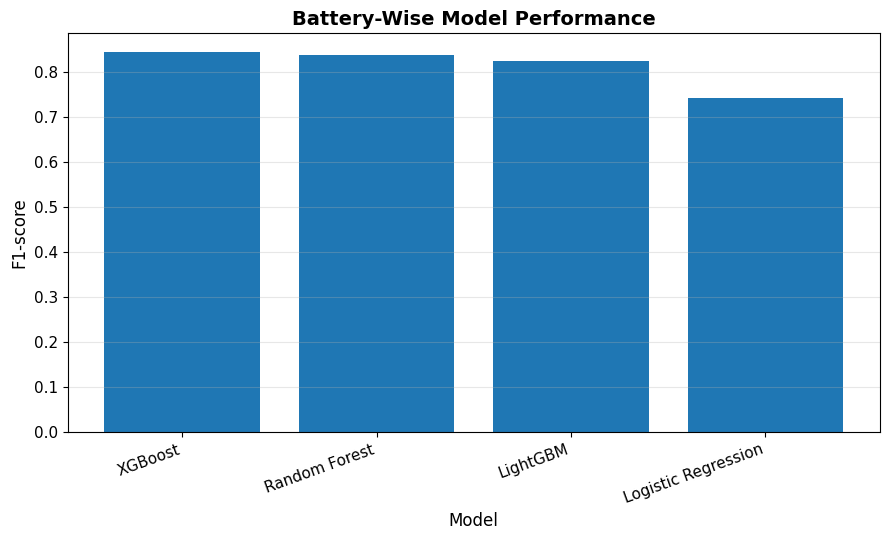

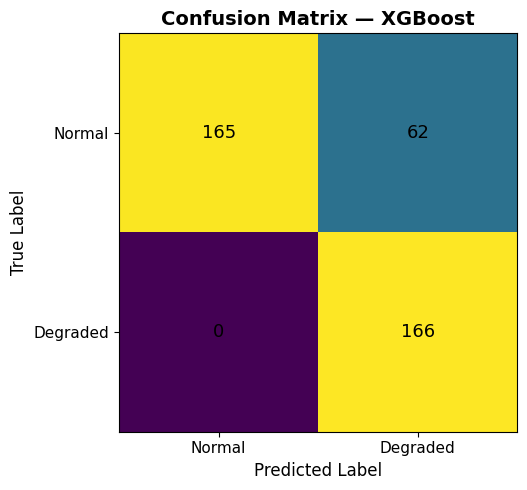


STEP 3 COMPLETE


In [11]:
# ============================================================
# STEP 3 — BATTERY-WISE MACHINE LEARNING EXPERIMENT
# ============================================================

import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ------------------------------------------------------------
# 2. LOAD RESEARCH DATASET
# ------------------------------------------------------------

DATA_PATH = Path(
    "/content/Battery_EarlyWarning_Dataset.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Research dataset not found: {DATA_PATH}"
    )

data = pd.read_csv(DATA_PATH)


# ------------------------------------------------------------
# 3. FEATURES AND TARGET
# ------------------------------------------------------------

FEATURES = [
    "ambient_temperature",
    "cycle_no",
    "log_cycle",
    "Re",
    "Rct",
    "delta_Re",
    "delta_Rct",
    "Re_drift_pct",
    "Rct_drift_pct",
    "Rct_Re_ratio",
]

TARGET = "next_degraded"

X = data[FEATURES].copy()
y = data[TARGET].astype(int).copy()

groups = data["battery_id"].copy()


# ------------------------------------------------------------
# 4. BATTERY-WISE TRAIN / TEST SPLIT
# ------------------------------------------------------------

unique_batteries = np.sort(
    groups.unique()
)

rng = np.random.default_rng(SEED)

shuffled_batteries = rng.permutation(
    unique_batteries
)

n_test_batteries = max(
    1,
    int(round(0.20 * len(unique_batteries)))
)

test_batteries = np.sort(
    shuffled_batteries[:n_test_batteries]
)

train_batteries = np.sort(
    shuffled_batteries[n_test_batteries:]
)


# ------------------------------------------------------------
# 5. CREATE MASKS
# ------------------------------------------------------------

train_mask = groups.isin(
    train_batteries
)

test_mask = groups.isin(
    test_batteries
)


X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()


# ------------------------------------------------------------
# 6. DISPLAY SPLIT
# ------------------------------------------------------------

print("=" * 70)
print("BATTERY-WISE EXPERIMENTAL SPLIT")
print("=" * 70)

print(
    f"Total batteries       : "
    f"{len(unique_batteries)}"
)

print(
    f"Training batteries    : "
    f"{len(train_batteries)}"
)

print(
    f"Testing batteries     : "
    f"{len(test_batteries)}"
)

print(
    f"Training observations : "
    f"{len(X_train):,}"
)

print(
    f"Testing observations  : "
    f"{len(X_test):,}"
)

print(
    f"\nTraining batteries:\n"
    f"{train_batteries}"
)

print(
    f"\nTesting batteries:\n"
    f"{test_batteries}"
)


# ------------------------------------------------------------
# 7. CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

print("\nTraining:")
print(
    y_train.value_counts()
    .sort_index()
)

print("\nTesting:")
print(
    y_test.value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 8. CLASS IMBALANCE WEIGHT
# ------------------------------------------------------------

negative_count = (
    y_train == 0
).sum()

positive_count = (
    y_train == 1
).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(
    f"\nScale positive weight : "
    f"{scale_pos_weight:.4f}"
)


# ------------------------------------------------------------
# 9. DEFINE MODELS
# ------------------------------------------------------------

models = {

    "Logistic Regression": Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=3000,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
    ),

    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        n_jobs=-1,
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=400,
        max_depth=-1,
        num_leaves=31,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        class_weight="balanced",
        random_state=SEED,
        verbosity=-1,
        n_jobs=-1,
    ),
}


# ------------------------------------------------------------
# 10. MODEL TRAINING
# ------------------------------------------------------------

results = []

predictions = {}

probabilities = {}

trained_models = {}


print("\n" + "=" * 70)
print("MODEL TRAINING")
print("=" * 70)


for model_name, model in models.items():

    print(
        f"\nTraining {model_name}..."
    )

    model.fit(
        X_train,
        y_train,
    )

    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    trained_models[model_name] = model

    predictions[model_name] = y_pred

    probabilities[model_name] = y_prob


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred,
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred,
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0,
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0,
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0,
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob,
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob,
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred,
    )

    results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy,
            "Balanced_Accuracy": balanced_acc,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": roc_auc,
            "PR_AUC": pr_auc,
            "MCC": mcc,
        }
    )


# ------------------------------------------------------------
# 11. RESULTS TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

results_df = results_df.sort_values(
    "F1",
    ascending=False,
).reset_index(drop=True)


print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

print(
    results_df.round(4).to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 12. BEST MODEL
# ------------------------------------------------------------

best_model_name = (
    results_df
    .iloc[0]["Model"]
)

print("\n" + "=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    f"Selected using test F1: "
    f"{best_model_name}"
)


# ------------------------------------------------------------
# 13. DETAILED REPORT FOR BEST MODEL
# ------------------------------------------------------------

best_predictions = predictions[
    best_model_name
]

best_probabilities = probabilities[
    best_model_name
]

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Normal",
            "Degraded",
        ],
        digits=4,
        zero_division=0,
    )
)


# ------------------------------------------------------------
# 14. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    best_predictions,
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)


# ------------------------------------------------------------
# 15. SAVE RESULTS
# ------------------------------------------------------------

results_path = (
    "/content/Table_II_Model_Comparison.csv"
)

results_df.to_csv(
    results_path,
    index=False,
)

print(
    f"\nResults saved to:\n"
    f"{results_path}"
)


# ------------------------------------------------------------
# 16. FIGURE — MODEL F1 COMPARISON
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5.5)
)

plt.bar(
    results_df["Model"],
    results_df["F1"],
)

plt.ylabel(
    "F1-score",
    fontsize=12,
)

plt.xlabel(
    "Model",
    fontsize=12,
)

plt.title(
    "Battery-Wise Model Performance",
    fontsize=14,
    fontweight="bold",
)

plt.xticks(
    rotation=20,
    ha="right",
    fontsize=11,
)

plt.yticks(
    fontsize=11
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

plt.savefig(
    "/content/Figure_4_model_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    "/content/Figure_4_model_comparison.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 17. CONFUSION MATRIX FIGURE
# ------------------------------------------------------------

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    cm,
    interpolation="nearest",
)

plt.title(
    f"Confusion Matrix — {best_model_name}",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel(
    "Predicted Label",
    fontsize=12,
)

plt.ylabel(
    "True Label",
    fontsize=12,
)

plt.xticks(
    [0, 1],
    ["Normal", "Degraded"],
    fontsize=11,
)

plt.yticks(
    [0, 1],
    ["Normal", "Degraded"],
    fontsize=11,
)


for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=13,
        )


plt.tight_layout()

plt.savefig(
    "/content/Figure_5_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    "/content/Figure_5_confusion_matrix.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("\n" + "=" * 70)
print("STEP 3 COMPLETE")
print("=" * 70)

5-FOLD BATTERY-WISE CROSS-VALIDATION

----------------------------------------------------------------------
FOLD 1
----------------------------------------------------------------------
Training batteries : 27
Validation batteries: 7
Training samples    : 2,153
Validation samples  : 528
Validation degraded : 6.63%

----------------------------------------------------------------------
FOLD 2
----------------------------------------------------------------------
Training batteries : 27
Validation batteries: 7
Training samples    : 2,238
Validation samples  : 443
Validation degraded : 81.04%

----------------------------------------------------------------------
FOLD 3
----------------------------------------------------------------------
Training batteries : 24
Validation batteries: 10
Training samples    : 1,682
Validation samples  : 999
Validation degraded : 18.12%

----------------------------------------------------------------------
FOLD 4
-----------------------------------------

,Model,Accuracy_Mean,Accuracy_Std,Balanced_Accuracy_Mean,Balanced_Accuracy_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std,MCC_Mean,MCC_Std
0,Logistic Regression,0.8419,0.0801,0.7848,0.0634,0.6492,0.1441,0.8650,0.1378,0.7333,0.1206,0.8707,0.1182,0.8094,0.0937,0.5793,0.0456
1,Random Forest,0.8520,0.1245,0.7595,0.1456,0.7396,0.2392,0.6886,0.2385,0.7082,0.2280,0.8823,0.1324,0.7678,0.2572,0.5257,0.2948
2,XGBoost,0.8969,0.0839,0.8119,0.1549,0.7832,0.1716,0.8087,0.2297,0.7929,0.1983,0.8986,0.1157,0.7939,0.2228,0.6273,0.2944
3,LightGBM,0.8840,0.0822,0.7924,0.1471,0.7553,0.2418,0.7699,0.2069,0.7609,0.2218,0.8531,0.1971,0.7760,0.2196,0.5840,0.3037



OUT-OF-FOLD PERFORMANCE
              Model  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC    MCC
Logistic Regression    0.8452             0.8689     0.6740  0.9271 0.7805   0.9190  0.7979 0.6857
      Random Forest    0.8844             0.8557     0.8181  0.7852 0.8013   0.9397  0.8194 0.7201
            XGBoost    0.9112             0.9013     0.8329  0.8769 0.8543   0.9546  0.8605 0.7911
           LightGBM    0.8978             0.8816     0.8191  0.8417 0.8302   0.9451  0.8126 0.7573

ROBUSTNESS-BASED MODEL SELECTION
Best OOF F1 model : XGBoost


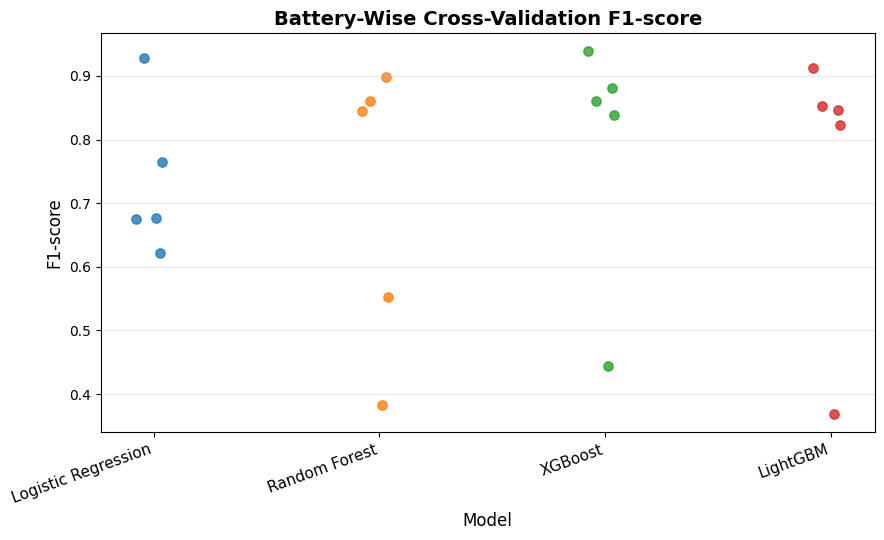


STEP 4 COMPLETE


In [12]:
# ============================================================
# STEP 4 — 5-FOLD BATTERY-WISE CROSS-VALIDATION
# ============================================================

import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ------------------------------------------------------------
# 2. LOAD RESEARCH DATASET
# ------------------------------------------------------------

DATA_PATH = (
    "/content/Battery_EarlyWarning_Dataset.csv"
)

data = pd.read_csv(DATA_PATH)


# ------------------------------------------------------------
# 3. FEATURES
# ------------------------------------------------------------

FEATURES = [
    "ambient_temperature",
    "cycle_no",
    "log_cycle",
    "Re",
    "Rct",
    "delta_Re",
    "delta_Rct",
    "Re_drift_pct",
    "Rct_drift_pct",
    "Rct_Re_ratio",
]

TARGET = "next_degraded"

X = data[FEATURES].copy()
y = data[TARGET].astype(int).copy()

groups = data["battery_id"].copy()


# ------------------------------------------------------------
# 4. CROSS-VALIDATION
# ------------------------------------------------------------

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)


# ------------------------------------------------------------
# 5. MODEL FACTORY
# ------------------------------------------------------------

def create_models(
    y_train: pd.Series,
) -> dict:
    """
    Create fresh model instances for one CV fold.
    """

    negative = (y_train == 0).sum()
    positive = (y_train == 1).sum()

    scale_pos_weight = (
        negative / positive
    )

    models = {

        "Logistic Regression": Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    LogisticRegression(
                        max_iter=3000,
                        class_weight="balanced",
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1,
        ),

        "XGBoost": XGBClassifier(
            n_estimators=400,
            max_depth=5,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=SEED,
            n_jobs=-1,
        ),

        "LightGBM": LGBMClassifier(
            n_estimators=400,
            num_leaves=31,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.85,
            class_weight="balanced",
            random_state=SEED,
            verbosity=-1,
            n_jobs=-1,
        ),
    }

    return models


# ------------------------------------------------------------
# 6. STORAGE
# ------------------------------------------------------------

fold_results = []

oof_predictions = {
    "Logistic Regression": np.zeros(len(data)),
    "Random Forest": np.zeros(len(data)),
    "XGBoost": np.zeros(len(data)),
    "LightGBM": np.zeros(len(data)),
}

oof_probabilities = {
    "Logistic Regression": np.zeros(len(data)),
    "Random Forest": np.zeros(len(data)),
    "XGBoost": np.zeros(len(data)),
    "LightGBM": np.zeros(len(data)),
}


# ------------------------------------------------------------
# 7. CROSS-VALIDATION LOOP
# ------------------------------------------------------------

print("=" * 70)
print("5-FOLD BATTERY-WISE CROSS-VALIDATION")
print("=" * 70)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(
        X,
        y,
        groups,
    ),
    start=1,
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_groups = set(
        groups.iloc[train_idx]
    )

    test_groups = set(
        groups.iloc[test_idx]
    )

    overlap = (
        train_groups
        .intersection(test_groups)
    )

    if overlap:
        raise RuntimeError(
            f"Battery leakage detected: {overlap}"
        )

    print("\n" + "-" * 70)
    print(f"FOLD {fold}")
    print("-" * 70)

    print(
        f"Training batteries : "
        f"{len(train_groups)}"
    )

    print(
        f"Validation batteries: "
        f"{len(test_groups)}"
    )

    print(
        f"Training samples    : "
        f"{len(train_idx):,}"
    )

    print(
        f"Validation samples  : "
        f"{len(test_idx):,}"
    )

    print(
        f"Validation degraded : "
        f"{y_test.mean():.2%}"
    )

    models = create_models(
        y_train
    )

    for model_name, model in models.items():

        model.fit(
            X_train,
            y_train,
        )

        y_pred = model.predict(
            X_test
        )

        y_prob = model.predict_proba(
            X_test
        )[:, 1]

        # Store OOF predictions
        oof_predictions[
            model_name
        ][test_idx] = y_pred

        oof_probabilities[
            model_name
        ][test_idx] = y_prob

        # Metrics
        fold_results.append(
            {
                "Fold": fold,
                "Model": model_name,
                "Accuracy": accuracy_score(
                    y_test,
                    y_pred,
                ),
                "Balanced_Accuracy": (
                    balanced_accuracy_score(
                        y_test,
                        y_pred,
                    )
                ),
                "Precision": precision_score(
                    y_test,
                    y_pred,
                    zero_division=0,
                ),
                "Recall": recall_score(
                    y_test,
                    y_pred,
                    zero_division=0,
                ),
                "F1": f1_score(
                    y_test,
                    y_pred,
                    zero_division=0,
                ),
                "ROC_AUC": roc_auc_score(
                    y_test,
                    y_prob,
                ),
                "PR_AUC": average_precision_score(
                    y_test,
                    y_prob,
                ),
                "MCC": matthews_corrcoef(
                    y_test,
                    y_pred,
                ),
            }
        )


# ------------------------------------------------------------
# 8. FOLD RESULTS
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(
    fold_results
)

print("\n" + "=" * 70)
print("FOLD-BY-FOLD RESULTS")
print("=" * 70)

print(
    fold_results_df.round(4).to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 9. MEAN ± STANDARD DEVIATION
# ------------------------------------------------------------

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC",
    "MCC",
]

summary_rows = []

for model_name in [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
]:

    subset = fold_results_df[
        fold_results_df["Model"]
        == model_name
    ]

    row = {
        "Model": model_name,
    }

    for metric in metric_columns:

        row[
            f"{metric}_Mean"
        ] = subset[metric].mean()

        row[
            f"{metric}_Std"
        ] = subset[metric].std()

    summary_rows.append(row)


summary_df = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# 10. DISPLAY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("5-FOLD BATTERY-WISE SUMMARY")
print("=" * 70)

display(
    summary_df.round(4)
)


# ------------------------------------------------------------
# 11. OOF PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OUT-OF-FOLD PERFORMANCE")
print("=" * 70)

oof_rows = []

for model_name in oof_predictions:

    y_pred = oof_predictions[
        model_name
    ]

    y_prob = oof_probabilities[
        model_name
    ]

    oof_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(
                y,
                y_pred,
            ),
            "Balanced_Accuracy": (
                balanced_accuracy_score(
                    y,
                    y_pred,
                )
            ),
            "Precision": precision_score(
                y,
                y_pred,
                zero_division=0,
            ),
            "Recall": recall_score(
                y,
                y_pred,
                zero_division=0,
            ),
            "F1": f1_score(
                y,
                y_pred,
                zero_division=0,
            ),
            "ROC_AUC": roc_auc_score(
                y,
                y_prob,
            ),
            "PR_AUC": average_precision_score(
                y,
                y_prob,
            ),
            "MCC": matthews_corrcoef(
                y,
                y_pred,
            ),
        }
    )


oof_df = pd.DataFrame(
    oof_rows
)

print(
    oof_df.round(4).to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 12. SAVE TABLE
# ------------------------------------------------------------

summary_df.to_csv(
    "/content/Table_III_CV_Summary.csv",
    index=False,
)

fold_results_df.to_csv(
    "/content/Table_III_Fold_Results.csv",
    index=False,
)

oof_df.to_csv(
    "/content/Table_III_OOF_Performance.csv",
    index=False,
)


# ------------------------------------------------------------
# 13. SELECT BEST MODEL
# ------------------------------------------------------------

best_idx = oof_df[
    "F1"
].idxmax()

best_model_name = oof_df.loc[
    best_idx,
    "Model",
]

print("\n" + "=" * 70)
print("ROBUSTNESS-BASED MODEL SELECTION")
print("=" * 70)

print(
    f"Best OOF F1 model : "
    f"{best_model_name}"
)


# ------------------------------------------------------------
# 14. FIGURE — F1 DISTRIBUTION
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5.5)
)

models_order = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
]

for position, model_name in enumerate(
    models_order
):

    subset = fold_results_df[
        fold_results_df["Model"]
        == model_name
    ]

    x_values = np.full(
        len(subset),
        position,
        dtype=float,
    )

    jitter = (
        np.random.default_rng(SEED)
        .normal(
            0,
            0.04,
            len(subset),
        )
    )

    plt.scatter(
        x_values + jitter,
        subset["F1"],
        s=45,
        alpha=0.8,
    )


plt.xticks(
    range(len(models_order)),
    models_order,
    rotation=20,
    ha="right",
    fontsize=11,
)

plt.ylabel(
    "F1-score",
    fontsize=12,
)

plt.xlabel(
    "Model",
    fontsize=12,
)

plt.title(
    "Battery-Wise Cross-Validation F1-score",
    fontsize=14,
    fontweight="bold",
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

plt.savefig(
    "/content/Figure_6_cv_f1_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    "/content/Figure_6_cv_f1_distribution.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("\n" + "=" * 70)
print("STEP 4 COMPLETE")
print("=" * 70)

FINAL IEEE FIGURE GENERATION
Research samples : 2,681
Batteries        : 34

Generating Figure 1...


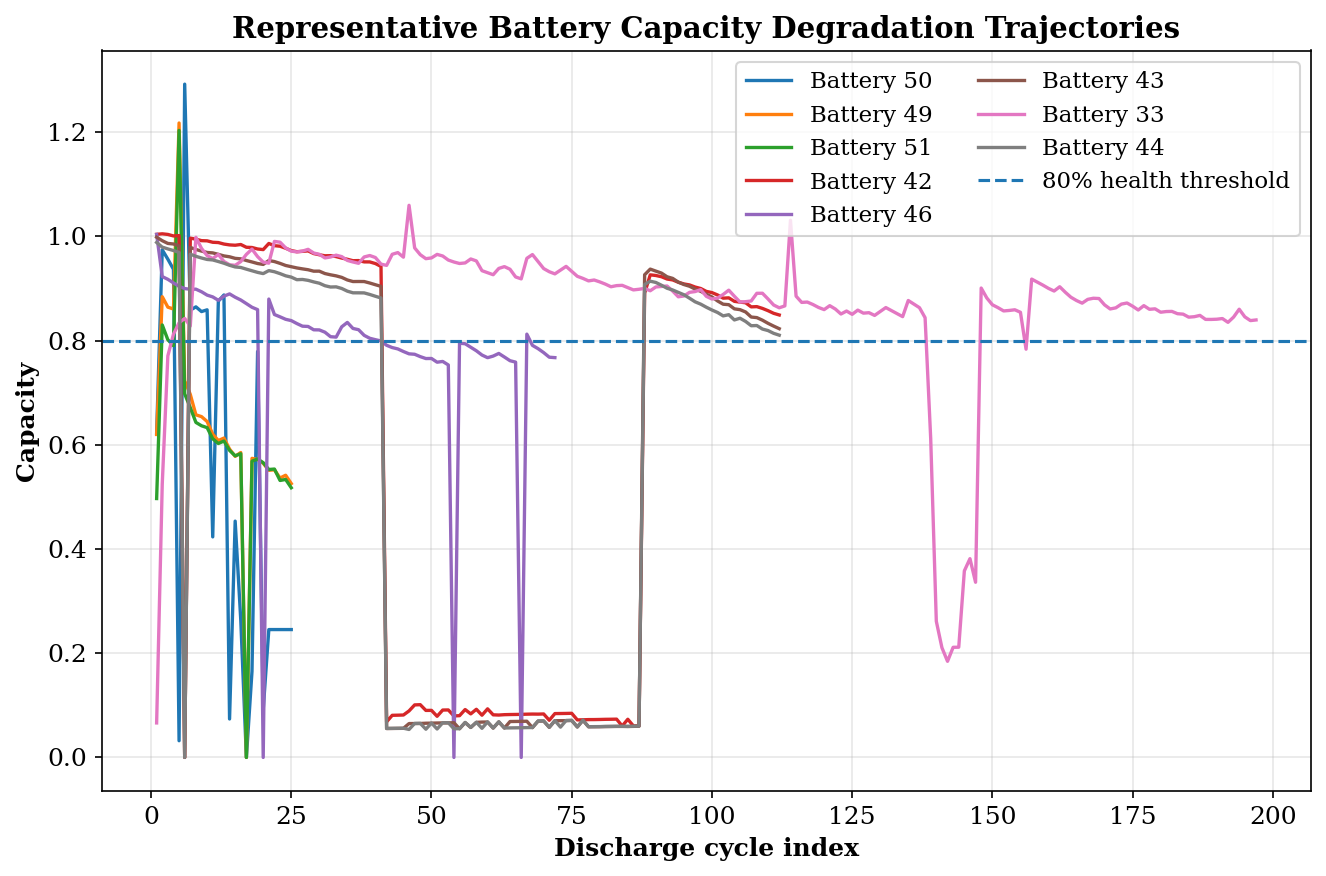

Saved: Figure_1_Capacity_Degradation.png
Saved: Figure_1_Capacity_Degradation.pdf

Generating Figure 2...


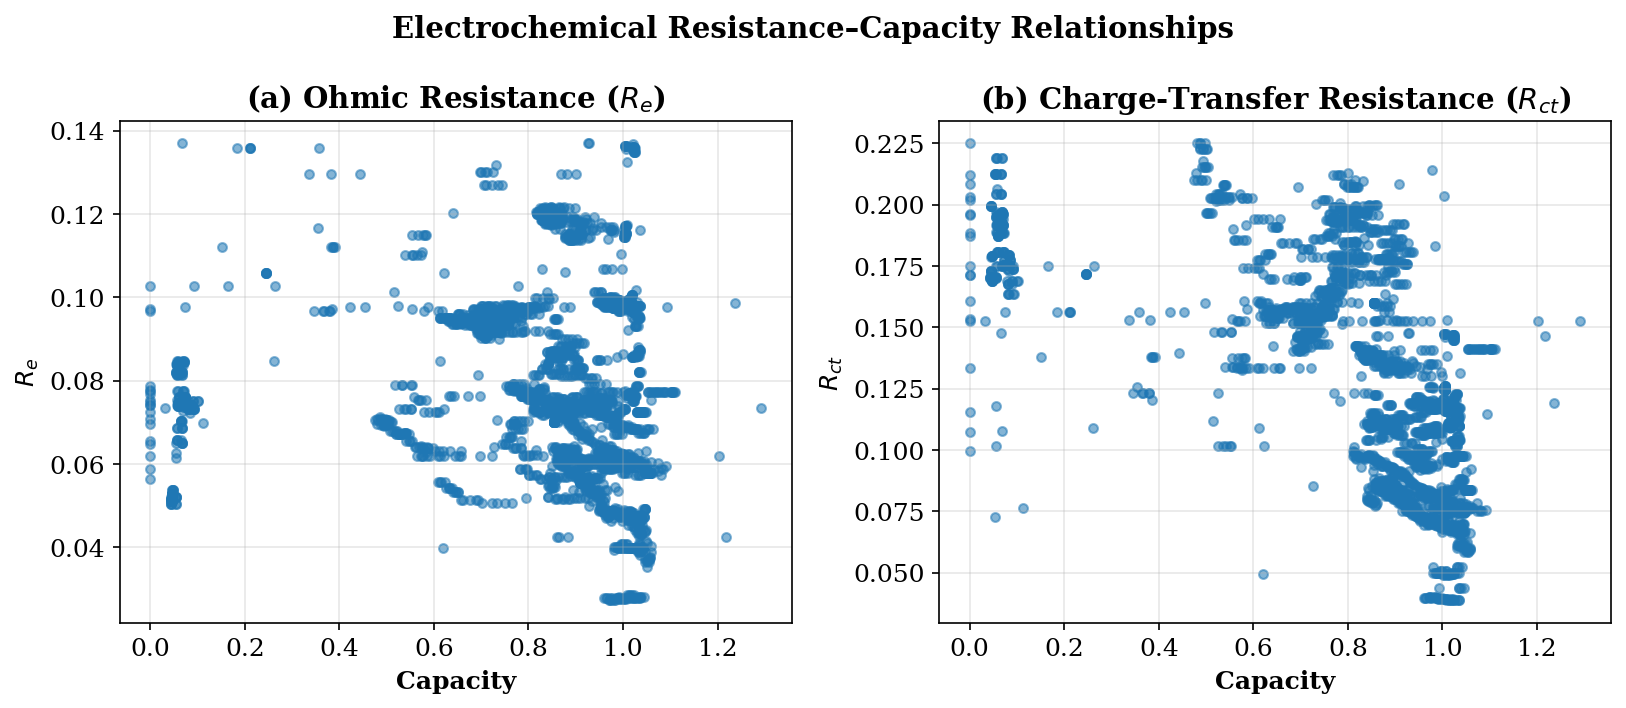

Saved: Figure_2_Resistance_Capacity.png
Saved: Figure_2_Resistance_Capacity.pdf

Generating Figure 3...


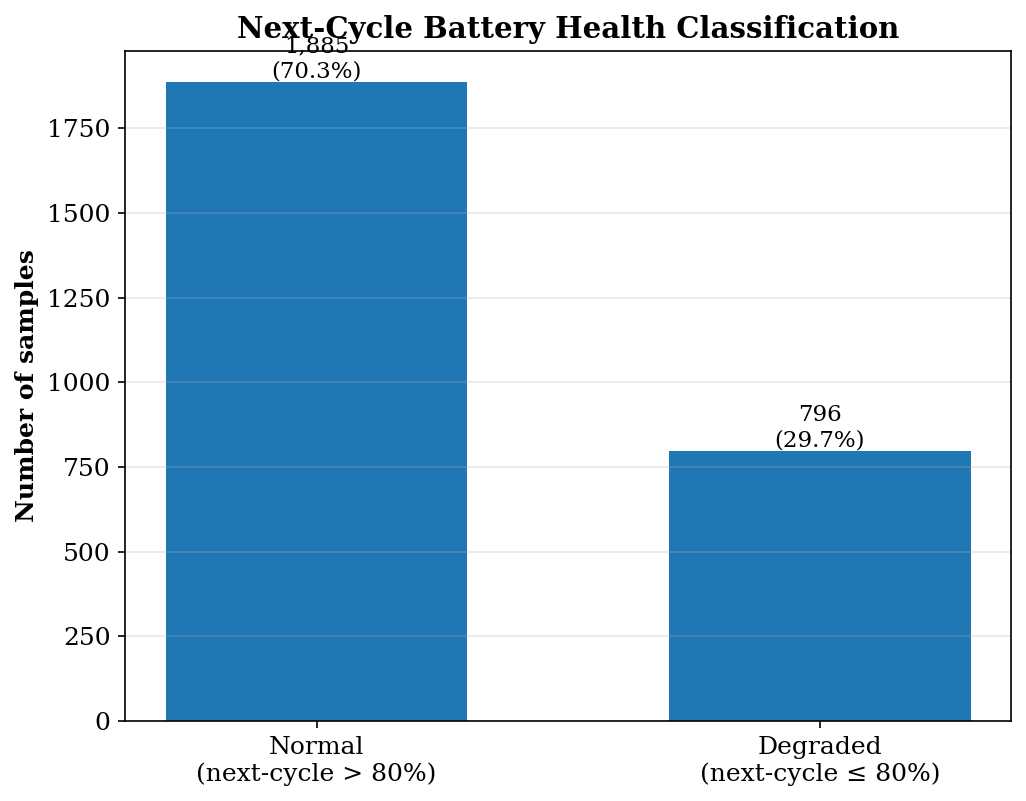

Saved: Figure_3_Class_Distribution.png
Saved: Figure_3_Class_Distribution.pdf

Generating Figure 4...


/tmp/ipykernel_2097/246086095.py:467: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_2097/246086095.py:467: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_2097/246086095.py:467: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


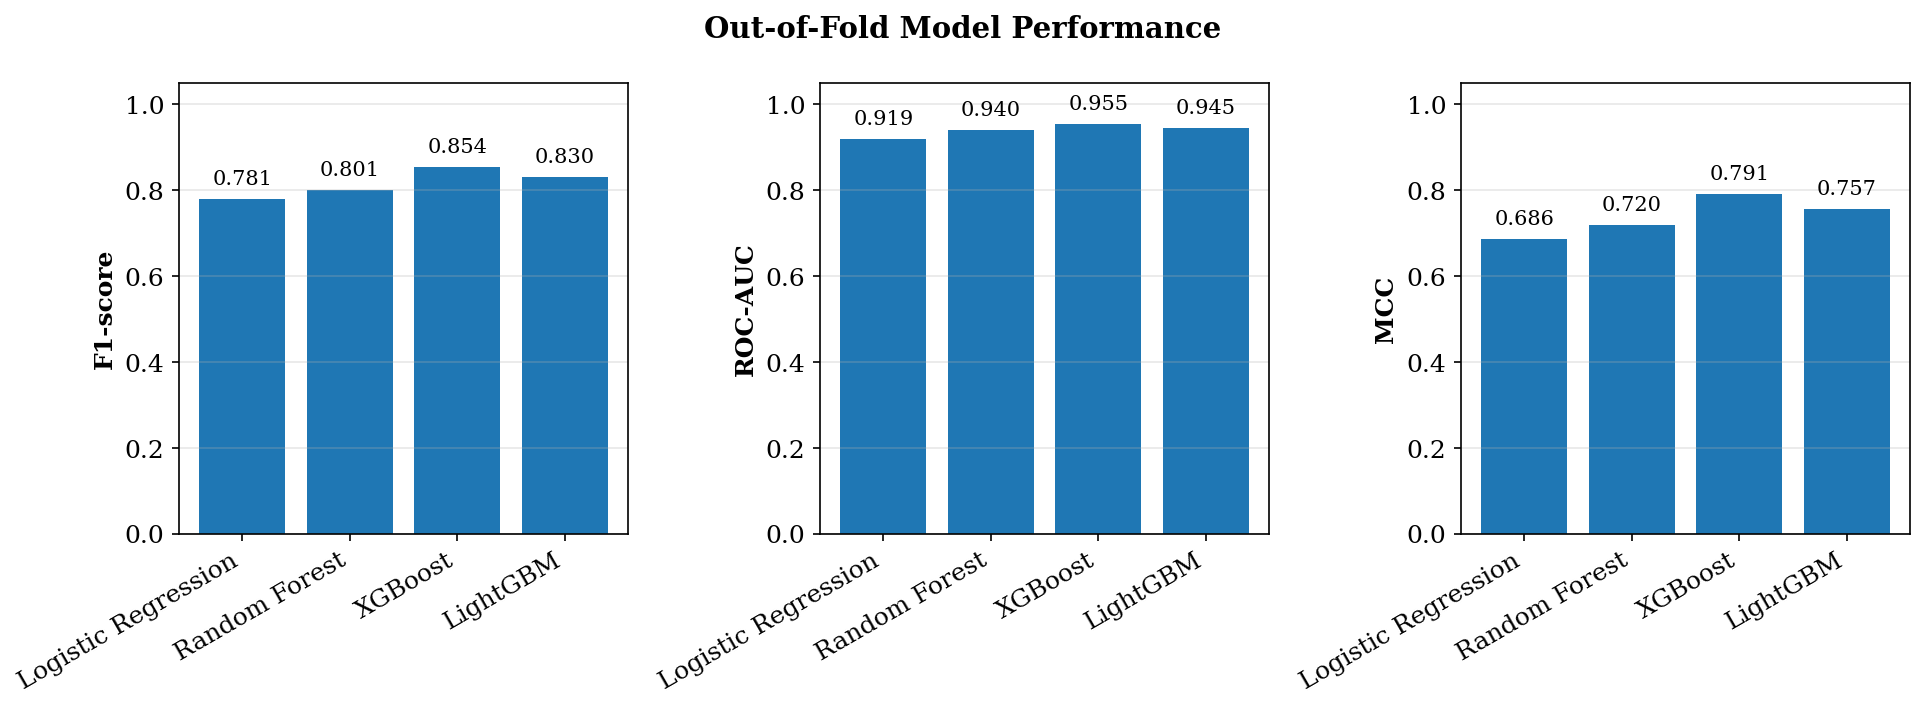

Saved: Figure_4_Model_Performance.png
Saved: Figure_4_Model_Performance.pdf

Generating Figure 5...


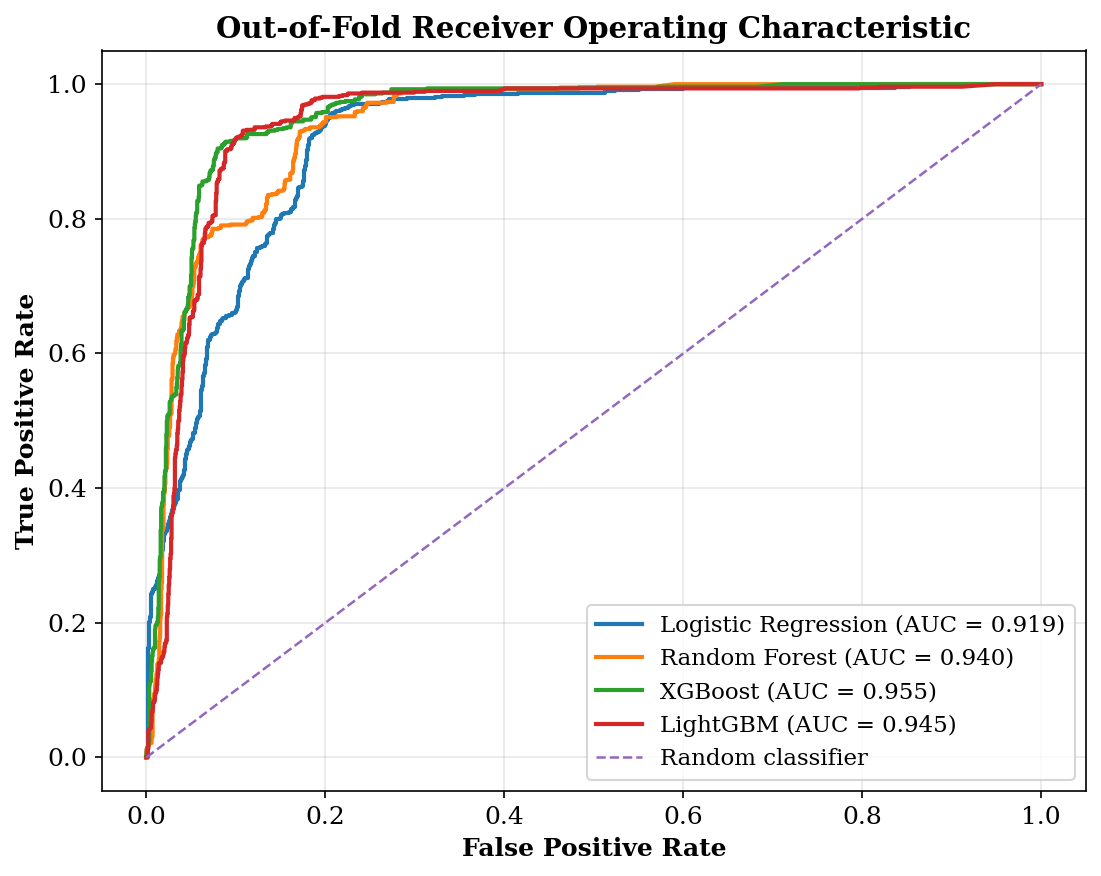

Saved: Figure_5_ROC_Curves.png
Saved: Figure_5_ROC_Curves.pdf

Generating Figure 6...


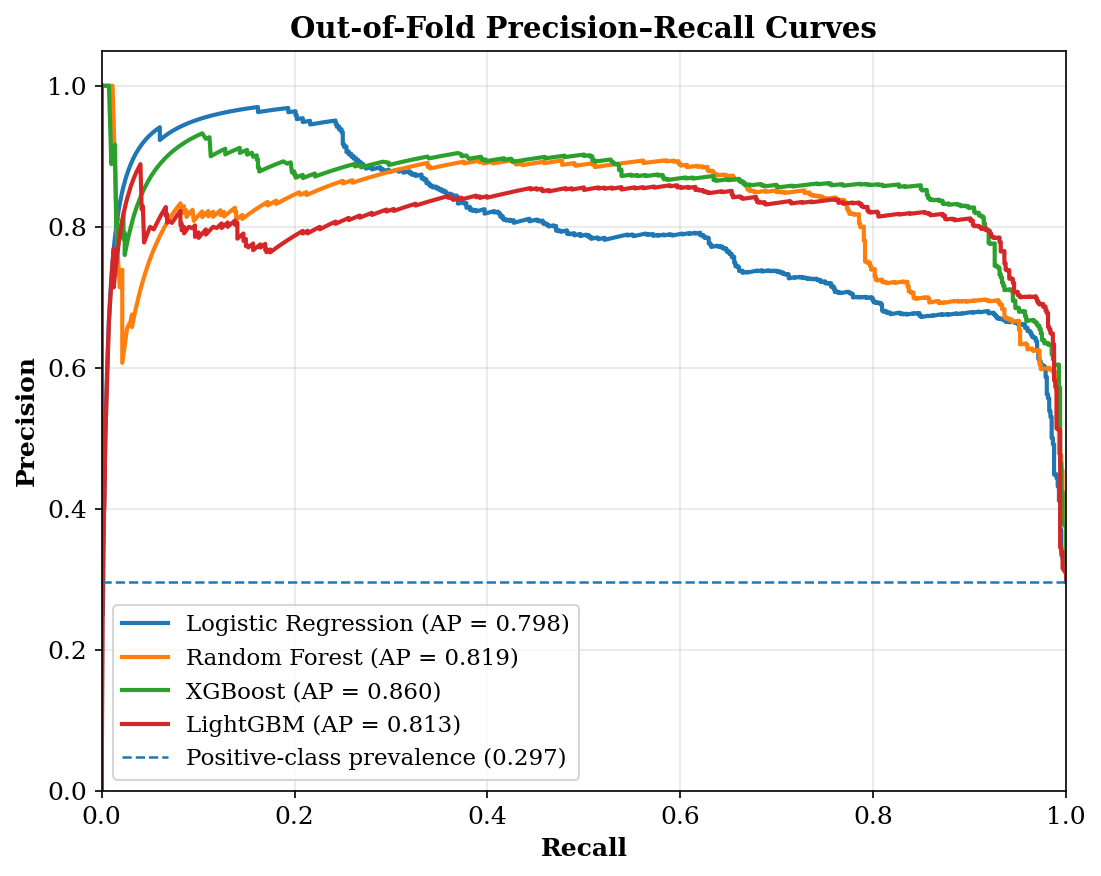

Saved: Figure_6_Precision_Recall.png
Saved: Figure_6_Precision_Recall.pdf

Generating Figure 7...


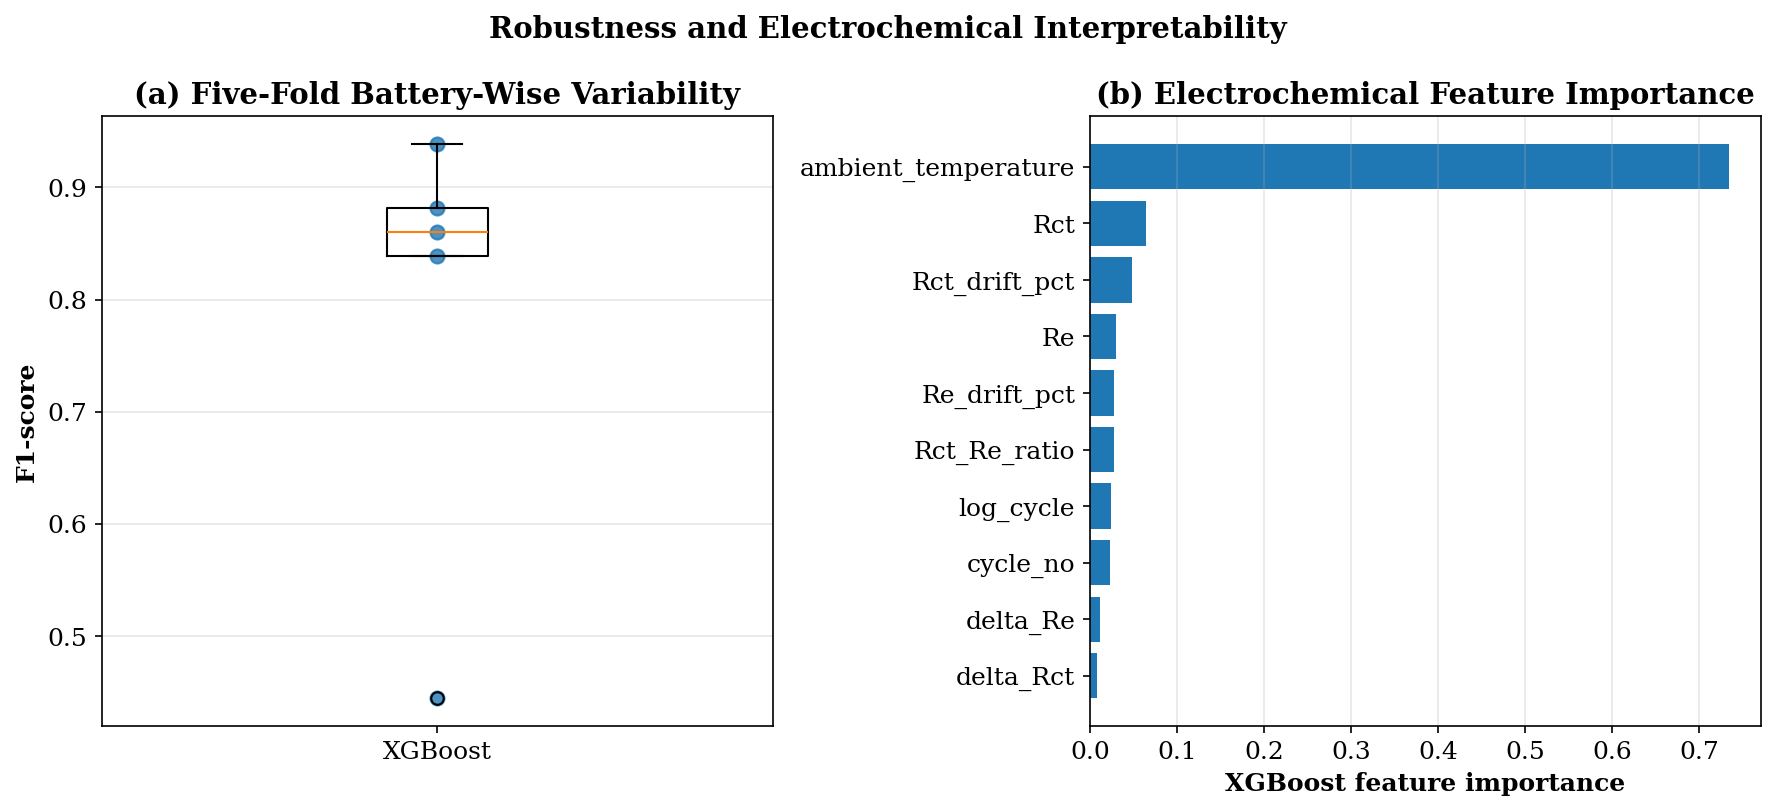

Saved: Figure_7_Robustness_Feature_Importance.png
Saved: Figure_7_Robustness_Feature_Importance.pdf

FINAL FIGURE PACKAGE CREATED
PNG figures : 7
PDF figures : 7
Folder      : /content/Battery_IEEE_Final_Figures
ZIP         : /content/Battery_IEEE_Final_Figures.zip

Files:
  Figure_1_Capacity_Degradation.pdf
  Figure_1_Capacity_Degradation.png
  Figure_2_Resistance_Capacity.pdf
  Figure_2_Resistance_Capacity.png
  Figure_3_Class_Distribution.pdf
  Figure_3_Class_Distribution.png
  Figure_4_Model_Performance.pdf
  Figure_4_Model_Performance.png
  Figure_5_ROC_Curves.pdf
  Figure_5_ROC_Curves.png
  Figure_6_Precision_Recall.pdf
  Figure_6_Precision_Recall.png
  Figure_7_Robustness_Feature_Importance.pdf
  Figure_7_Robustness_Feature_Importance.png
  Figure_Manifest.csv

STEP 5 COMPLETE.


In [17]:
# ============================================================
# STEP 5 — FINAL IEEE FIGURES
# Battery Degradation Early-Warning Study
# ============================================================

from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
)

from xgboost import XGBClassifier


# ============================================================
# 1. IEEE PLOTTING CONFIGURATION
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "DejaVu Serif",
    ],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "figure.dpi": 150,
    "savefig.dpi": 300,
})


# ============================================================
# 2. OUTPUT DIRECTORY
# ============================================================

FIG_DIR = Path(
    "/content/Battery_IEEE_Final_Figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 3. LOAD RESEARCH DATASET
# ============================================================

research_path = Path(
    "/content/Battery_EarlyWarning_Dataset.csv"
)

if not research_path.exists():
    raise FileNotFoundError(
        "Battery_EarlyWarning_Dataset.csv "
        "was not found."
    )

research_df = pd.read_csv(
    research_path
)

print("=" * 70)
print("FINAL IEEE FIGURE GENERATION")
print("=" * 70)

print(
    f"Research samples : {len(research_df):,}"
)

print(
    f"Batteries        : "
    f"{research_df['battery_id'].nunique()}"
)


# ============================================================
# HELPER FUNCTION
# ============================================================

def save_figure(
    fig: plt.Figure,
    filename: str,
) -> None:
    """
    Save figure as high-resolution PNG and PDF.
    """

    png_path = FIG_DIR / f"{filename}.png"
    pdf_path = FIG_DIR / f"{filename}.pdf"

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(fig)

    print(
        f"Saved: {filename}.png"
    )

    print(
        f"Saved: {filename}.pdf"
    )


# ============================================================
# FIGURE 1
# BATTERY CAPACITY DEGRADATION TRAJECTORIES
# ============================================================

print("\nGenerating Figure 1...")

original_discharge = df[
    df["type"] == -1
].copy()

original_discharge = (
    original_discharge
    .sort_values(
        ["battery_id", "test_id"]
    )
)

# Select representative batteries based on
# degradation span and available samples.

battery_ranges = (
    original_discharge
    .groupby("battery_id")
    .agg(
        n=("Capacity", "size"),
        capacity_min=("Capacity", "min"),
        capacity_max=("Capacity", "max"),
    )
)

battery_ranges["drop"] = (
    battery_ranges["capacity_max"]
    - battery_ranges["capacity_min"]
)

selected_batteries = (
    battery_ranges
    .sort_values(
        "drop",
        ascending=False,
    )
    .head(8)
    .index
)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

for battery_id in selected_batteries:

    battery_data = (
        original_discharge[
            original_discharge["battery_id"]
            == battery_id
        ]
        .sort_values("test_id")
    )

    cycle = np.arange(
        1,
        len(battery_data) + 1,
    )

    ax.plot(
        cycle,
        battery_data["Capacity"],
        linewidth=1.6,
        label=f"Battery {battery_id}",
    )


ax.axhline(
    0.80,
    linestyle="--",
    linewidth=1.5,
    label="80% health threshold",
)

ax.set_xlabel(
    "Discharge cycle index"
)

ax.set_ylabel(
    "Capacity"
)

ax.set_title(
    "Representative Battery Capacity Degradation Trajectories"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend(
    ncol=2,
    frameon=True,
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_1_Capacity_Degradation",
)


# ============================================================
# FIGURE 2
# ELECTROCHEMICAL RESISTANCE VS CAPACITY
# ============================================================

print("\nGenerating Figure 2...")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.8),
)

# ------------------------------------------------------------
# Re
# ------------------------------------------------------------

axes[0].scatter(
    original_discharge["Capacity"],
    original_discharge["Re"],
    s=18,
    alpha=0.55,
)

axes[0].set_xlabel(
    "Capacity"
)

axes[0].set_ylabel(
    r"$R_e$"
)

axes[0].set_title(
    r"(a) Ohmic Resistance ($R_e$)"
)

axes[0].grid(
    True,
    alpha=0.3,
)


# ------------------------------------------------------------
# Rct
# ------------------------------------------------------------

axes[1].scatter(
    original_discharge["Capacity"],
    original_discharge["Rct"],
    s=18,
    alpha=0.55,
)

axes[1].set_xlabel(
    "Capacity"
)

axes[1].set_ylabel(
    r"$R_{ct}$"
)

axes[1].set_title(
    r"(b) Charge-Transfer Resistance ($R_{ct}$)"
)

axes[1].grid(
    True,
    alpha=0.3,
)


fig.suptitle(
    "Electrochemical Resistance–Capacity Relationships",
    fontsize=14,
    fontweight="bold",
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_2_Resistance_Capacity",
)


# ============================================================
# FIGURE 3
# NEXT-CYCLE DEGRADATION CLASS DISTRIBUTION
# ============================================================

print("\nGenerating Figure 3...")

class_counts = (
    research_df["next_degraded"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

labels = [
    "Normal\n(next-cycle > 80%)",
    "Degraded\n(next-cycle ≤ 80%)",
]

values = [
    class_counts.get(0, 0),
    class_counts.get(1, 0),
]

bars = ax.bar(
    labels,
    values,
    width=0.60,
)

ax.set_ylabel(
    "Number of samples"
)

ax.set_title(
    "Next-Cycle Battery Health Classification"
)

ax.grid(
    axis="y",
    alpha=0.3,
)

for bar, value in zip(
    bars,
    values,
):

    percentage = (
        value / sum(values) * 100
    )

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value,
        f"{value:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
    )

fig.tight_layout()

save_figure(
    fig,
    "Figure_3_Class_Distribution",
)


# ============================================================
# FIGURE 4
# OUT-OF-FOLD MODEL COMPARISON
# ============================================================

print("\nGenerating Figure 4...")

# Use existing OOF dataframe generated in Step 4.
if "oof_df" not in globals():

    oof_path = Path(
        "/content/Table_III_OOF_Performance.csv"
    )

    if not oof_path.exists():
        raise FileNotFoundError(
            "OOF performance file not found."
        )

    oof_df = pd.read_csv(
        oof_path
    )


model_order = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
]

plot_df = (
    oof_df
    .set_index("Model")
    .loc[model_order]
    .reset_index()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4.8),
)

metrics = [
    ("F1", "F1-score"),
    ("ROC_AUC", "ROC-AUC"),
    ("MCC", "MCC"),
]

for ax, (metric, ylabel) in zip(
    axes,
    metrics,
):

    bars = ax.bar(
        plot_df["Model"],
        plot_df[metric],
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.set_xticklabels(
        plot_df["Model"],
        rotation=30,
        ha="right",
    )

    ax.grid(
        axis="y",
        alpha=0.3,
    )

    for bar, value in zip(
        bars,
        plot_df[metric],
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            value + 0.025,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=10,
        )


fig.suptitle(
    "Out-of-Fold Model Performance",
    fontsize=14,
    fontweight="bold",
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_4_Model_Performance",
)


# ============================================================
# FIGURE 5
# OUT-OF-FOLD ROC CURVES
# ============================================================

print("\nGenerating Figure 5...")

if "oof_probabilities" not in globals():
    raise RuntimeError(
        "oof_probabilities is not available. "
        "Run Step 4 in the same Colab runtime."
    )

fig, ax = plt.subplots(
    figsize=(7.5, 6)
)

for model_name in model_order:

    probabilities = (
        oof_probabilities[model_name]
    )

    fpr, tpr, _ = roc_curve(
        research_df["next_degraded"],
        probabilities,
    )

    auc_value = (
        oof_df.loc[
            oof_df["Model"] == model_name,
            "ROC_AUC",
        ]
        .iloc[0]
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{model_name} "
            f"(AUC = {auc_value:.3f})"
        ),
    )


ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    label="Random classifier",
)

ax.set_xlabel(
    "False Positive Rate"
)

ax.set_ylabel(
    "True Positive Rate"
)

ax.set_title(
    "Out-of-Fold Receiver Operating Characteristic"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend(
    loc="lower right",
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_5_ROC_Curves",
)


# ============================================================
# FIGURE 6
# OUT-OF-FOLD PRECISION-RECALL CURVES
# ============================================================

print("\nGenerating Figure 6...")

fig, ax = plt.subplots(
    figsize=(7.5, 6)
)

positive_rate = (
    research_df["next_degraded"]
    .mean()
)

for model_name in model_order:

    probabilities = (
        oof_probabilities[model_name]
    )

    precision, recall, _ = (
        precision_recall_curve(
            research_df["next_degraded"],
            probabilities,
        )
    )

    pr_auc = (
        oof_df.loc[
            oof_df["Model"] == model_name,
            "PR_AUC",
        ]
        .iloc[0]
    )

    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=(
            f"{model_name} "
            f"(AP = {pr_auc:.3f})"
        ),
    )


ax.axhline(
    positive_rate,
    linestyle="--",
    linewidth=1.2,
    label=(
        f"Positive-class prevalence "
        f"({positive_rate:.3f})"
    ),
)

ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "Out-of-Fold Precision–Recall Curves"
)

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.05
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend(
    loc="lower left",
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_6_Precision_Recall",
)


# ============================================================
# FIGURE 7
# CROSS-VALIDATION VARIABILITY + FEATURE IMPORTANCE
# ============================================================

print("\nGenerating Figure 7...")

# ------------------------------------------------------------
# Train final XGBoost only for feature interpretation.
# This model is NOT used to report predictive performance.
# ------------------------------------------------------------

X_all = research_df[
    [
        "ambient_temperature",
        "cycle_no",
        "log_cycle",
        "Re",
        "Rct",
        "delta_Re",
        "delta_Rct",
        "Re_drift_pct",
        "Rct_drift_pct",
        "Rct_Re_ratio",
    ]
]

y_all = research_df[
    "next_degraded"
]

negative_count = (
    y_all == 0
).sum()

positive_count = (
    y_all == 1
).sum()

scale_pos_weight = (
    negative_count
    / positive_count
)

interpretation_model = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.04,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
)

interpretation_model.fit(
    X_all,
    y_all,
)

importance = pd.Series(
    interpretation_model.feature_importances_,
    index=X_all.columns,
).sort_values(
    ascending=True
)


# ------------------------------------------------------------
# CV DATA
# ------------------------------------------------------------

if "fold_results_df" not in globals():

    fold_path = Path(
        "/content/Table_III_Fold_Results.csv"
    )

    if not fold_path.exists():
        raise FileNotFoundError(
            "Fold results file not found."
        )

    fold_results_df = pd.read_csv(
        fold_path
    )

xgb_cv = fold_results_df[
    fold_results_df["Model"]
    == "XGBoost"
].copy()


# ------------------------------------------------------------
# TWO-PANEL FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5.5),
)

# ------------------------------------------------------------
# Panel A — F1 variability
# ------------------------------------------------------------

axes[0].boxplot(
    xgb_cv["F1"],
    vert=True,
)

axes[0].scatter(
    np.ones(len(xgb_cv)),
    xgb_cv["F1"],
    s=45,
    alpha=0.8,
)

axes[0].set_xticks(
    [1]
)

axes[0].set_xticklabels(
    ["XGBoost"]
)

axes[0].set_ylabel(
    "F1-score"
)

axes[0].set_title(
    "(a) Five-Fold Battery-Wise Variability"
)

axes[0].grid(
    axis="y",
    alpha=0.3,
)


# ------------------------------------------------------------
# Panel B — Feature importance
# ------------------------------------------------------------

axes[1].barh(
    importance.index,
    importance.values,
)

axes[1].set_xlabel(
    "XGBoost feature importance"
)

axes[1].set_title(
    "(b) Electrochemical Feature Importance"
)

axes[1].grid(
    axis="x",
    alpha=0.3,
)


fig.suptitle(
    "Robustness and Electrochemical Interpretability",
    fontsize=14,
    fontweight="bold",
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_7_Robustness_Feature_Importance",
)


# ============================================================
# 4. CREATE FIGURE MANIFEST
# ============================================================

manifest = pd.DataFrame(
    {
        "Figure": [
            "Figure 1",
            "Figure 2",
            "Figure 3",
            "Figure 4",
            "Figure 5",
            "Figure 6",
            "Figure 7",
        ],
        "Description": [
            "Representative battery capacity degradation trajectories",
            "Ohmic and charge-transfer resistance versus capacity",
            "Next-cycle degradation class distribution",
            "Out-of-fold model performance",
            "Out-of-fold ROC curves",
            "Out-of-fold precision-recall curves",
            "Cross-validation variability and XGBoost feature importance",
        ],
    }
)

manifest.to_csv(
    FIG_DIR / "Figure_Manifest.csv",
    index=False,
)


# ============================================================
# 5. ZIP ALL FIGURES
# ============================================================

ZIP_PATH = Path(
    "/content/Battery_IEEE_Final_Figures.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as zip_file:

    for file_path in FIG_DIR.iterdir():

        if file_path.is_file():

            zip_file.write(
                file_path,
                arcname=file_path.name,
            )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL FIGURE PACKAGE CREATED")
print("=" * 70)

png_files = list(
    FIG_DIR.glob("*.png")
)

pdf_files = list(
    FIG_DIR.glob("*.pdf")
)

print(
    f"PNG figures : {len(png_files)}"
)

print(
    f"PDF figures : {len(pdf_files)}"
)

print(
    f"Folder      : {FIG_DIR}"
)

print(
    f"ZIP         : {ZIP_PATH}"
)

print("\nFiles:")

for file_path in sorted(
    FIG_DIR.iterdir()
):

    print(
        f"  {file_path.name}"
    )

print("\nSTEP 5 COMPLETE.")

In [18]:
# ============================================================
# PACKAGE ALL IEEE FIGURES + TABLES
# ============================================================

from pathlib import Path
import shutil
import zipfile
import pandas as pd


# ------------------------------------------------------------
# 1. DIRECTORIES
# ------------------------------------------------------------

BASE_DIR = Path("/content")

FIG_DIR = BASE_DIR / "Battery_IEEE_Final_Figures"
TABLE_DIR = BASE_DIR / "Battery_IEEE_Final_Tables"
PACKAGE_DIR = BASE_DIR / "Battery_IEEE_Final_Results"

# IMPORTANT: parents=True fixes the previous error
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. CREATE TABLE I
# ------------------------------------------------------------

table1 = pd.DataFrame({
    "Parameter": [
        "Total observations",
        "Number of batteries",
        "Discharge observations",
        "Final early-warning samples",
        "Samples per battery",
        "Ambient temperature range",
        "Capacity range",
        "Re range",
        "Rct range",
        "Normal next-cycle samples",
        "Degraded next-cycle samples",
        "Degraded-class proportion",
        "Model input features",
        "Missing values",
    ],
    "Value": [
        "7,368",
        "34",
        "2,749",
        "2,681",
        "23–195",
        "4–44",
        "0–1.292",
        "0.0267–0.1421",
        "0.0388–0.2381",
        "1,885",
        "796",
        "29.69%",
        "10",
        "0",
    ],
})

table1.to_csv(
    TABLE_DIR / "Table_I_Dataset_Characteristics.csv",
    index=False,
)


# ------------------------------------------------------------
# 3. CREATE TABLE II
# ------------------------------------------------------------

table2 = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM",
    ],
    "Accuracy": [0.8452, 0.8844, 0.9112, 0.8978],
    "Balanced Accuracy": [0.8689, 0.8557, 0.9013, 0.8816],
    "Precision": [0.6740, 0.8181, 0.8329, 0.8191],
    "Recall": [0.9271, 0.7852, 0.8769, 0.8417],
    "F1-score": [0.7805, 0.8013, 0.8543, 0.8302],
    "ROC-AUC": [0.9190, 0.9397, 0.9546, 0.9451],
    "PR-AUC": [0.7979, 0.8194, 0.8605, 0.8126],
    "MCC": [0.6857, 0.7201, 0.7911, 0.7573],
})

table2.to_csv(
    TABLE_DIR / "Table_II_OOF_Model_Comparison.csv",
    index=False,
)


# ------------------------------------------------------------
# 4. CREATE TABLE III
# ------------------------------------------------------------

table3 = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM",
    ],
    "Accuracy": [
        "0.8419 ± 0.0801",
        "0.8520 ± 0.1245",
        "0.8969 ± 0.0839",
        "0.8840 ± 0.0822",
    ],
    "Balanced Accuracy": [
        "0.7848 ± 0.0634",
        "0.7595 ± 0.1456",
        "0.8119 ± 0.1549",
        "0.7924 ± 0.1471",
    ],
    "Precision": [
        "0.6492 ± 0.1441",
        "0.7396 ± 0.2392",
        "0.7832 ± 0.1716",
        "0.7553 ± 0.2418",
    ],
    "Recall": [
        "0.8650 ± 0.1378",
        "0.6886 ± 0.2385",
        "0.8087 ± 0.2297",
        "0.7699 ± 0.2069",
    ],
    "F1-score": [
        "0.7333 ± 0.1206",
        "0.7082 ± 0.2280",
        "0.7929 ± 0.1983",
        "0.7609 ± 0.2218",
    ],
    "ROC-AUC": [
        "0.8707 ± 0.1182",
        "0.8823 ± 0.1324",
        "0.8986 ± 0.1157",
        "0.8531 ± 0.1971",
    ],
    "MCC": [
        "0.5793 ± 0.0456",
        "0.5257 ± 0.2948",
        "0.6273 ± 0.2944",
        "0.5840 ± 0.3037",
    ],
})

table3.to_csv(
    TABLE_DIR / "Table_III_FiveFold_Robustness.csv",
    index=False,
)


# ------------------------------------------------------------
# 5. COPY EXISTING STEP-4 TABLES IF AVAILABLE
# ------------------------------------------------------------

existing_tables = [
    "Table_III_Fold_Results.csv",
    "Table_III_OOF_Performance.csv",
]

for filename in existing_tables:

    source = BASE_DIR / filename

    if source.exists():

        shutil.copy2(
            source,
            TABLE_DIR / filename,
        )


# ------------------------------------------------------------
# 6. CHECK FIGURES
# ------------------------------------------------------------

figure_names = [
    "Figure_1_Capacity_Degradation",
    "Figure_2_Resistance_Capacity",
    "Figure_3_Class_Distribution",
    "Figure_4_Model_Performance",
    "Figure_5_ROC_Curves",
    "Figure_6_Precision_Recall",
    "Figure_7_Robustness_Feature_Importance",
]

missing_figures = []

for figure_name in figure_names:

    for extension in [".png", ".pdf"]:

        source = (
            FIG_DIR
            / f"{figure_name}{extension}"
        )

        if not source.exists():
            missing_figures.append(
                f"{figure_name}{extension}"
            )


# ------------------------------------------------------------
# 7. COPY FIGURES AND TABLES INTO FINAL PACKAGE
# ------------------------------------------------------------

for old_file in PACKAGE_DIR.iterdir():

    if old_file.is_file():
        old_file.unlink()


# Copy figures
for file in FIG_DIR.iterdir():

    if file.suffix.lower() in [
        ".png",
        ".pdf",
    ]:

        shutil.copy2(
            file,
            PACKAGE_DIR / file.name,
        )


# Copy tables
for file in TABLE_DIR.iterdir():

    if file.suffix.lower() == ".csv":

        shutil.copy2(
            file,
            PACKAGE_DIR / file.name,
        )


# ------------------------------------------------------------
# 8. CREATE MANIFEST
# ------------------------------------------------------------

manifest = pd.DataFrame({
    "Item": [
        "Figure 1",
        "Figure 2",
        "Figure 3",
        "Figure 4",
        "Figure 5",
        "Figure 6",
        "Figure 7",
        "Table I",
        "Table II",
        "Table III",
    ],
    "Description": [
        "Capacity degradation trajectories",
        "Resistance-capacity relationships",
        "Next-cycle class distribution",
        "OOF model performance",
        "OOF ROC curves",
        "OOF precision-recall curves",
        "CV variability and feature importance",
        "Dataset characteristics",
        "OOF model comparison",
        "Five-fold robustness",
    ],
})

manifest.to_csv(
    PACKAGE_DIR / "IEEE_Results_Manifest.csv",
    index=False,
)


# ------------------------------------------------------------
# 9. CREATE ZIP FILE
# ------------------------------------------------------------

ZIP_PATH = (
    BASE_DIR
    / "Battery_IEEE_Final_Figures_Tables.zip"
)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()


with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as zip_file:

    for file in sorted(
        PACKAGE_DIR.iterdir()
    ):

        if file.is_file():

            zip_file.write(
                file,
                arcname=file.name,
            )


# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

package_files = sorted(
    PACKAGE_DIR.iterdir()
)

png_count = len(
    list(PACKAGE_DIR.glob("*.png"))
)

pdf_count = len(
    list(PACKAGE_DIR.glob("*.pdf"))
)

csv_count = len(
    list(PACKAGE_DIR.glob("*.csv"))
)


print("=" * 75)
print("IEEE FINAL RESULTS PACKAGE")
print("=" * 75)

print(
    f"\nPNG figures : {png_count}"
)

print(
    f"PDF figures : {pdf_count}"
)

print(
    f"CSV tables  : {csv_count}"
)

print(
    f"\nFolder:"
)

print(
    PACKAGE_DIR
)

print(
    f"\nZIP:"
)

print(
    ZIP_PATH
)

print("\nPACKAGE CONTENTS")
print("-" * 75)

for file in package_files:
    print(
        f"✓ {file.name}"
    )


if missing_figures:

    print("\nWARNING — Missing figures:")

    for filename in missing_figures:
        print(
            f"  ! {filename}"
        )

    print(
        "\nRun STEP 5 figure-generation code first."
    )

else:

    print(
        "\n✓ All 7 figures found."
    )

print(
    "\n✓ Table I created."
)

print(
    "✓ Table II created."
)

print(
    "✓ Table III created."
)

print(
    "✓ Final ZIP package created."
)

print(
    "\nSTEP 6 COMPLETE."
)

IEEE FINAL RESULTS PACKAGE

PNG figures : 7
PDF figures : 7
CSV tables  : 6

Folder:
/content/Battery_IEEE_Final_Results

ZIP:
/content/Battery_IEEE_Final_Figures_Tables.zip

PACKAGE CONTENTS
---------------------------------------------------------------------------
✓ Figure_1_Capacity_Degradation.pdf
✓ Figure_1_Capacity_Degradation.png
✓ Figure_2_Resistance_Capacity.pdf
✓ Figure_2_Resistance_Capacity.png
✓ Figure_3_Class_Distribution.pdf
✓ Figure_3_Class_Distribution.png
✓ Figure_4_Model_Performance.pdf
✓ Figure_4_Model_Performance.png
✓ Figure_5_ROC_Curves.pdf
✓ Figure_5_ROC_Curves.png
✓ Figure_6_Precision_Recall.pdf
✓ Figure_6_Precision_Recall.png
✓ Figure_7_Robustness_Feature_Importance.pdf
✓ Figure_7_Robustness_Feature_Importance.png
✓ IEEE_Results_Manifest.csv
✓ Table_III_FiveFold_Robustness.csv
✓ Table_III_Fold_Results.csv
✓ Table_III_OOF_Performance.csv
✓ Table_II_OOF_Model_Comparison.csv
✓ Table_I_Dataset_Characteristics.csv

✓ All 7 figures found.

✓ Table I created.
✓ Table

In [19]:
from google.colab import files

files.download(
    "/content/Battery_IEEE_Final_Figures_Tables.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>